In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Libraries imported successfully!")

Libraries imported successfully.


In [ ]:
df = pd.read_csv("/content/multi_platform_social_sentiment_evolution.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (150000, 31)


In [ ]:
display(df.head())

,post_id,platform,timestamp,date,hour_of_day,day_of_week,is_weekend,user_id,followers,account_age_days,...,shares,comments,views,total_engagement,engagement_rate_per_1k_followers,hours_since_post,viral_coefficient,cross_platform_spread,toxicity_score,location
0,TIK20250419000000,TikTok,2025-04-19 01:56:55,2025-04-19,1,5,1,user_426711,137,306,...,0,0,0,0,0.00,37.1,0.00,0,29.4,Asia
1,TWI20250419000001,Twitter,2025-04-19 05:34:09,2025-04-19,5,5,1,user_221610,1974,2310,...,0,0,105,3,1.52,37.1,0.08,0,3.3,South America
2,INS20250419000002,Instagram,2025-04-19 06:33:36,2025-04-19,6,5,1,user_7998,6471,1990,...,0,0,26,2,0.31,21.0,0.10,0,25.3,Europe
3,INS20250419000003,Instagram,2025-04-19 06:42:16,2025-04-19,6,5,1,user_313440,1366,2057,...,16,8,3057,98,71.74,47.1,2.08,0,3.1,Europe
4,RED20250419000004,Reddit,2025-04-19 06:46:49,2025-04-19,6,5,1,user_23343,1349,1445,...,0,0,0,0,0.00,10.0,0.00,0,52.7,Asia


In [ ]:
print("Columns:")
print(df.columns.tolist())

Columns:
['post_id', 'platform', 'timestamp', 'date', 'hour_of_day', 'day_of_week', 'is_weekend', 'user_id', 'followers', 'account_age_days', 'verified', 'topic', 'language', 'content_length', 'media_type', 'num_hashtags', 'sentiment_category', 'sentiment_positive', 'sentiment_negative', 'sentiment_neutral', 'likes', 'shares', 'comments', 'views', 'total_engagement', 'engagement_rate_per_1k_followers', 'hours_since_post', 'viral_coefficient', 'cross_platform_spread', 'toxicity_score', 'location']


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nData types:")
print(df.dtypes)

Number of rows: 150000
Number of columns: 31

Data types:
post_id                              object
platform                             object
timestamp                            object
date                                 object
hour_of_day                           int64
day_of_week                           int64
is_weekend                            int64
user_id                              object
followers                             int64
account_age_days                      int64
verified                              int64
topic                                object
language                             object
content_length                        int64
media_type                           object
num_hashtags                          int64
sentiment_category                   object
sentiment_positive                  float64
sentiment_negative                  float64
sentiment_neutral                   float64
likes                                 int64
shares            

In [ ]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values:
post_id                             0
platform                            0
timestamp                           0
date                                0
hour_of_day                         0
day_of_week                         0
is_weekend                          0
user_id                             0
followers                           0
account_age_days                    0
verified                            0
topic                               0
language                            0
content_length                      0
media_type                          0
num_hashtags                        0
sentiment_category                  0
sentiment_positive                  0
sentiment_negative                  0
sentiment_neutral                   0
likes                               0
shares                              0
comments                            0
views                               0
total_engagement                    0
engagement_rate_per_1k_followers  

In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


In [ ]:
print("Target classes:")
print(df["sentiment_category"].value_counts())

print("\nTarget percentages:")
print(
    df["sentiment_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target classes:
sentiment_category
Positive    67597
Neutral     45110
Negative    37293
Name: count, dtype: int64

Target percentages:
sentiment_category
Positive    45.06
Neutral     30.07
Negative    24.86
Name: proportion, dtype: float64


In [ ]:
print("Number of target classes:",
      df["sentiment_category"].nunique())

print("Classes:",
      df["sentiment_category"].unique())

Number of target classes: 3
Classes: ['Neutral' 'Positive' 'Negative']


In [ ]:
df["account_age_years"] = (
    df["account_age_days"] / 365.25
)

In [ ]:
df["engagement_per_view"] = (
    df["total_engagement"] /
    (df["views"] + 1)
)

In [ ]:
df["like_ratio"] = (
    df["likes"] /
    (df["total_engagement"] + 1)
)

In [ ]:
df["share_ratio"] = (
    df["shares"] /
    (df["total_engagement"] + 1)
)

In [ ]:
df["comment_ratio"] = (
    df["comments"] /
    (df["total_engagement"] + 1)
)

In [ ]:
df["engagement_velocity"] = (
    df["total_engagement"] /
    (df["hours_since_post"] + 1)
)

In [ ]:
df["view_velocity"] = (
    df["views"] /
    (df["hours_since_post"] + 1)
)

In [ ]:
df["hashtag_density"] = (
    df["num_hashtags"] /
    (df["content_length"] + 1)
)

In [ ]:
print("Shape after feature engineering:", df.shape)

Shape after feature engineering: (150000, 39)


In [ ]:
engineered_features = [
    "account_age_years",
    "engagement_per_view",
    "like_ratio",
    "share_ratio",
    "comment_ratio",
    "engagement_velocity",
    "view_velocity",
    "hashtag_density"
]

display(df[engineered_features].head())

,account_age_years,engagement_per_view,like_ratio,share_ratio,comment_ratio,engagement_velocity,view_velocity,hashtag_density
0,0.837782,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.006757
1,6.324435,0.028302,0.750000,0.000000,0.000000,0.078740,2.755906,0.076923
2,5.448323,0.074074,0.666667,0.000000,0.000000,0.090909,1.181818,0.131579
3,5.631759,0.032047,0.747475,0.161616,0.080808,2.037422,63.555094,0.021053
4,3.956194,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.005970


In [ ]:
print(
    "Infinite values:",
    np.isinf(
        df[engineered_features]
        .select_dtypes(include=np.number)
    ).sum().sum()
)

Infinite values: 0


In [ ]:
target = "sentiment_category"

y = df[target].copy()

print(y.head())
print("\nTarget counts:")
print(y.value_counts())

0     Neutral
1    Positive
2    Positive
3    Positive
4    Positive
Name: sentiment_category, dtype: object

Target counts:
sentiment_category
Positive    67597
Neutral     45110
Negative    37293
Name: count, dtype: int64


In [ ]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

In [ ]:
print("Target mapping:")

for number, label in enumerate(label_encoder.classes_):
    print(f"{label} = {number}")

Target mapping:
Negative = 0
Neutral = 1
Positive = 2


In [ ]:
print("\nEncoded target counts:")
print(
    pd.Series(y_encoded)
    .value_counts()
    .sort_index()
)


Encoded target counts:
0    37293
1    45110
2    67597
Name: count, dtype: int64


In [ ]:
drop_cols = [
    # Target
    "sentiment_category",

    # Direct target leakage
    "sentiment_positive",
    "sentiment_negative",
    "sentiment_neutral",

    # Identifiers
    "post_id",
    "user_id",

    # Raw date/time fields
    "timestamp",
    "date",

    # Redundant because likes + shares + comments
    "total_engagement"
]

In [ ]:
X = df.drop(columns=drop_cols).copy()

print("Input shape:", X.shape)
print("Target shape:", y_encoded.shape)

Input shape: (150000, 30)
Target shape: (150000,)


In [ ]:
print("Model input columns:")

for column in X.columns:
    print(column)

Model input columns:
platform
hour_of_day
day_of_week
is_weekend
followers
account_age_days
verified
topic
language
content_length
media_type
num_hashtags
likes
shares
comments
views
engagement_rate_per_1k_followers
hours_since_post
viral_coefficient
cross_platform_spread
toxicity_score
location
account_age_years
engagement_per_view
like_ratio
share_ratio
comment_ratio
engagement_velocity
view_velocity
hashtag_density


In [ ]:
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

In [ ]:
print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

print("\nNumber of categorical columns:",
      len(categorical_cols))

print("Number of numerical columns:",
      len(numerical_cols))

Categorical columns:
['platform', 'topic', 'language', 'media_type', 'location']

Numerical columns:
['hour_of_day', 'day_of_week', 'is_weekend', 'followers', 'account_age_days', 'verified', 'content_length', 'num_hashtags', 'likes', 'shares', 'comments', 'views', 'engagement_rate_per_1k_followers', 'hours_since_post', 'viral_coefficient', 'cross_platform_spread', 'toxicity_score', 'account_age_years', 'engagement_per_view', 'like_ratio', 'share_ratio', 'comment_ratio', 'engagement_velocity', 'view_velocity', 'hashtag_density']

Number of categorical columns: 5
Number of numerical columns: 25


In [ ]:
for column in categorical_cols:
    print("\n============================")
    print("Column:", column)
    print("============================")
    print(X[column].value_counts())


Column: platform
platform
Twitter      44676
Reddit       37585
Instagram    30195
YouTube      18130
TikTok       11887
Facebook      7527
Name: count, dtype: int64

Column: topic
topic
Education        10138
Sports           10131
Technology       10127
Travel           10122
AI/ML            10110
Science          10048
Business         10019
Health           10016
Food             10009
Entertainment     9919
Politics          9910
Climate           9908
Fashion           9872
Finance           9870
Gaming            9801
Name: count, dtype: int64

Column: language
language
English       82385
Spanish       17861
Portuguese    12099
French         9007
Japanese       6107
German         5931
Korean         4554
Hindi          4532
Arabic         4527
Chinese        2997
Name: count, dtype: int64

Column: media_type
media_type
Text     52309
Image    45209
Video    30034
Link     14973
Poll      7475
Name: count, dtype: int64

Column: location
location
North America    52409
Asia  

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (120000, 30)
X_test : (30000, 30)
y_train: (120000,)
y_test : (30000,)


In [ ]:
print("Training target distribution:")
print(
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

Training target distribution:
0    29834
1    36088
2    54078
Name: count, dtype: int64


In [ ]:
print("\nTesting target distribution:")
print(
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)


Testing target distribution:
0     7459
1     9022
2    13519
Name: count, dtype: int64


In [ ]:
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_cols
        ),

        (
            "cat",
            categorical_transformer,
            categorical_cols
        )
    ]
)

In [ ]:
X_train_processed = preprocessor.fit_transform(
    X_train
)

In [ ]:
X_test_processed = preprocessor.transform(
    X_test
)

In [ ]:
print(
    "Original training shape:",
    X_train.shape
)

print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Original testing shape:",
    X_test.shape
)

print(
    "Processed testing shape:",
    X_test_processed.shape
)


Original training shape: (120000, 30)
Processed training shape: (120000, 68)
Original testing shape: (30000, 30)
Processed testing shape: (30000, 68)


In [ ]:
feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(
    "Total features after encoding:",
    len(feature_names)
)

Total features after encoding: 68


In [ ]:
for feature in feature_names:
    print(feature)

num__hour_of_day
num__day_of_week
num__is_weekend
num__followers
num__account_age_days
num__verified
num__content_length
num__num_hashtags
num__likes
num__shares
num__comments
num__views
num__engagement_rate_per_1k_followers
num__hours_since_post
num__viral_coefficient
num__cross_platform_spread
num__toxicity_score
num__account_age_years
num__engagement_per_view
num__like_ratio
num__share_ratio
num__comment_ratio
num__engagement_velocity
num__view_velocity
num__hashtag_density
cat__platform_Facebook
cat__platform_Instagram
cat__platform_Reddit
cat__platform_TikTok
cat__platform_Twitter
cat__platform_YouTube
cat__topic_AI/ML
cat__topic_Business
cat__topic_Climate
cat__topic_Education
cat__topic_Entertainment
cat__topic_Fashion
cat__topic_Finance
cat__topic_Food
cat__topic_Gaming
cat__topic_Health
cat__topic_Politics
cat__topic_Science
cat__topic_Sports
cat__topic_Technology
cat__topic_Travel
cat__language_Arabic
cat__language_Chinese
cat__language_English
cat__language_French
cat__langu

In [ ]:
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

In [ ]:
display(
    X_train_processed_df.head()
)

,num__hour_of_day,num__day_of_week,num__is_weekend,num__followers,num__account_age_days,num__verified,num__content_length,num__num_hashtags,num__likes,num__shares,...,cat__media_type_Poll,cat__media_type_Text,cat__media_type_Video,cat__location_Africa,cat__location_Asia,cat__location_Europe,cat__location_North America,cat__location_Oceania,cat__location_South America,cat__location_Unknown
147224,16.0,4.0,0.0,334.0,1635.0,0.0,172.0,0.0,3.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
6951,22.0,5.0,1.0,904.0,3105.0,0.0,103.0,2.0,6.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
97526,18.0,3.0,0.0,953.0,1680.0,0.0,247.0,3.0,3.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
106902,6.0,5.0,1.0,5398.0,398.0,0.0,58.0,4.0,75.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
14923,16.0,0.0,0.0,1188.0,289.0,0.0,275.0,1.0,11.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
print(
    X_train_processed_df
    .dtypes
    .value_counts()
)

float64    68
Name: count, dtype: int64


In [ ]:
object_columns = (
    X_train_processed_df
    .select_dtypes(include=["object"])
    .columns
)

print(
    "Object columns remaining:",
    len(object_columns)
)

Object columns remaining: 0


In [ ]:
print(
    "Training missing values:",
    X_train_processed_df
    .isnull()
    .sum()
    .sum()
)

print(
    "Testing missing values:",
    X_test_processed_df
    .isnull()
    .sum()
    .sum()
)

Training missing values: 0
Testing missing values: 0


In [ ]:
print(
    "Training infinite values:",
    np.isinf(
        X_train_processed_df
    ).sum().sum()
)

print(
    "Testing infinite values:",
    np.isinf(
        X_test_processed_df
    ).sum().sum()
)

Training infinite values: 0
Testing infinite values: 0


In [ ]:
print("=" * 60)
print("FINAL PREPROCESSING SUMMARY")
print("=" * 60)

print(
    "Dataset after feature engineering:",
    df.shape
)

print(
    "Model input before encoding:",
    X.shape
)

print(
    "Training records:",
    X_train.shape[0]
)

print(
    "Testing records:",
    X_test.shape[0]
)

print(
    "Categorical input columns:",
    len(categorical_cols)
)

print(
    "Numerical input columns:",
    len(numerical_cols)
)

print(
    "Features after encoding:",
    len(feature_names)
)

print(
    "Target classes:",
    label_encoder.classes_
)

print(
    "Missing training values:",
    X_train_processed_df
    .isnull()
    .sum()
    .sum()
)

print(
    "Missing testing values:",
    X_test_processed_df
    .isnull()
    .sum()
    .sum()
)

print("=" * 60)
print("DATA IS READY FOR MODEL TRAINING")
print("=" * 60)

FINAL PREPROCESSING SUMMARY
Dataset after feature engineering: (150000, 39)
Model input before encoding: (150000, 30)
Training records: 120000
Testing records: 30000
Categorical input columns: 5
Numerical input columns: 25
Features after encoding: 68
Target classes: ['Negative' 'Neutral' 'Positive']
Missing training values: 0
Missing testing values: 0
DATA IS READY FOR MODEL TRAINING


In [ ]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("Random Forest libraries imported successfully.")

Random Forest libraries imported successfully.


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print(rf_model)

RandomForestClassifier(class_weight='balanced', max_depth=20,
                       min_samples_leaf=2, min_samples_split=5,
                       n_estimators=300, n_jobs=-1, random_state=42)


In [ ]:
rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest training completed.")

Random Forest training completed.


In [ ]:
y_pred_rf = rf_model.predict(
    X_test_processed
)

print("Predictions generated successfully.")

Predictions generated successfully.


In [ ]:
print("First 20 actual values:")
print(y_test[:20])

print("\nFirst 20 predicted values:")
print(y_pred_rf[:20])

First 20 actual values:
[2 2 1 1 0 1 1 2 0 1 0 2 0 2 2 1 1 1 2 0]

First 20 predicted values:
[2 2 2 2 0 2 1 1 0 1 0 1 0 2 2 1 2 2 2 0]


In [ ]:
y_proba_rf = rf_model.predict_proba(
    X_test_processed
)

print("Probability shape:", y_proba_rf.shape)

print("\nFirst 5 probability predictions:")
print(y_proba_rf[:5])

Probability shape: (30000, 3)

First 5 probability predictions:
[[0.0400659  0.47099821 0.48893589]
 [0.06626959 0.41936437 0.51436604]
 [0.03727234 0.39021575 0.57251191]
 [0.04184444 0.43659645 0.5215591 ]
 [0.82661022 0.10706776 0.06632202]]


In [ ]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    round(rf_accuracy, 4)
)

print(
    "Random Forest Accuracy (%):",
    round(rf_accuracy * 100, 2),
    "%"
)

Random Forest Accuracy: 0.6621
Random Forest Accuracy (%): 66.21 %


In [ ]:
rf_precision = precision_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

print(
    "Random Forest Precision:",
    round(rf_precision, 4)
)

print(
    "Random Forest Precision (%):",
    round(rf_precision * 100, 2),
    "%"
)

Random Forest Precision: 0.6343
Random Forest Precision (%): 63.43 %


In [ ]:
rf_recall = recall_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

print(
    "Random Forest Recall:",
    round(rf_recall, 4)
)

print(
    "Random Forest Recall (%):",
    round(rf_recall * 100, 2),
    "%"
)

Random Forest Recall: 0.6621
Random Forest Recall (%): 66.21 %


In [ ]:
rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

print(
    "Random Forest F1 Score:",
    round(rf_f1, 4)
)

print(
    "Random Forest F1 Score (%):",
    round(rf_f1 * 100, 2),
    "%"
)

Random Forest F1 Score: 0.6358
Random Forest F1 Score (%): 63.58 %


In [ ]:
rf_auc = roc_auc_score(
    y_test,
    y_proba_rf,
    multi_class="ovr",
    average="weighted"
)

print(
    "Random Forest ROC-AUC:",
    round(rf_auc, 4)
)

print(
    "Random Forest ROC-AUC (%):",
    round(rf_auc * 100, 2),
    "%"
)

Random Forest ROC-AUC: 0.7899
Random Forest ROC-AUC (%): 78.99 %


In [ ]:
rf_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Score": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_auc
    ]
})

rf_results["Percentage"] = (
    rf_results["Score"] * 100
).round(2)

display(rf_results)

,Metric,Score,Percentage
0,Accuracy,0.662133,66.21
1,Precision,0.634350,63.43
2,Recall,0.662133,66.21
3,F1 Score,0.635803,63.58
4,ROC-AUC,0.789939,78.99


In [ ]:
rf_cm = confusion_matrix(
    y_test,
    y_pred_rf
)

print("Confusion Matrix:")
print(rf_cm)

Confusion Matrix:
[[ 6888   459   112]
 [  520  2198  6304]
 [  292  2449 10778]]


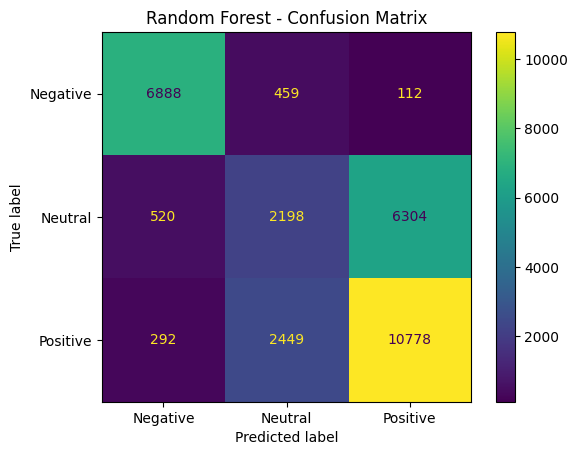

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=label_encoder.classes_
)

disp.plot(
    values_format="d"
)

plt.title(
    "Random Forest - Confusion Matrix"
)

plt.show()

In [ ]:
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(
    y_test,
    classes=[0, 1, 2]
)

print("Binary target shape:", y_test_bin.shape)

Binary target shape: (30000, 3)


In [ ]:
y_train_pred_rf = rf_model.predict(
    X_train_processed
)

rf_train_accuracy = accuracy_score(
    y_train,
    y_train_pred_rf
)

print(
    "Training Accuracy:",
    round(
        rf_train_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Testing Accuracy:",
    round(
        rf_accuracy * 100,
        2
    ),
    "%"
)

Training Accuracy: 93.2 %
Testing Accuracy: 66.21 %


In [ ]:
rf_overfit_gap = (
    rf_train_accuracy -
    rf_accuracy
)

print(
    "Train-Test Accuracy Gap:",
    round(
        rf_overfit_gap * 100,
        2
    ),
    "%"
)

Train-Test Accuracy Gap: 26.99 %


In [ ]:
rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

rf_feature_importance = (
    rf_feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
)

display(
    rf_feature_importance.head(20)
)

,Feature,Importance
16,num__toxicity_score,0.709042
3,num__followers,0.017756
6,num__content_length,0.017668
13,num__hours_since_post,0.017631
4,num__account_age_days,0.017510
17,num__account_age_years,0.017186
24,num__hashtag_density,0.016121
12,num__engagement_rate_per_1k_followers,0.012150
0,num__hour_of_day,0.011957
18,num__engagement_per_view,0.011410


In [ ]:
print("=" * 55)
print("RANDOM FOREST RESULTS")
print("=" * 55)

print(
    f"Training Accuracy : "
    f"{rf_train_accuracy * 100:.2f}%"
)

print(
    f"Testing Accuracy  : "
    f"{rf_accuracy * 100:.2f}%"
)

print(
    f"Precision         : "
    f"{rf_precision * 100:.2f}%"
)

print(
    f"Recall            : "
    f"{rf_recall * 100:.2f}%"
)

print(
    f"F1 Score          : "
    f"{rf_f1 * 100:.2f}%"
)

print(
    f"ROC-AUC           : "
    f"{rf_auc * 100:.2f}%"
)

print(
    f"Train-Test Gap    : "
    f"{rf_overfit_gap * 100:.2f}%"
)

print("=" * 55)

RANDOM FOREST RESULTS
Training Accuracy : 93.20%
Testing Accuracy  : 66.21%
Precision         : 63.43%
Recall            : 66.21%
F1 Score          : 63.58%
ROC-AUC           : 78.99%
Train-Test Gap    : 26.99%
